# Cuándo comprar evidencia antes de escalar IA

## Resumen
Caso sintético: el mejor candidato es un piloto de 50 observaciones con valor esperado neto 5.140,42 unidades frente a 0 al decidir hoy. El piloto fijo de 100 obtiene 5.138,22: la diferencia de diseño es pequeña, no una ventaja comercial demostrada.

## Lectura de los resultados ejecutados

Se reconstruyeron EVSI y EVPI y se estudió prior, costo y demora. El diseño elegido se restringe al grid sintético.

Resultados académicos adicionales (valores del experimento):

```json
{
  "sequential_value": 4796.377133033429,
  "fixed_best_value": 4601.805220780544,
  "horizon": 30,
  "states": 496
}
```

Datos sintéticos. Esta sección acompaña las salidas guardadas y no es una medición comercial o bancaria.

## Contexto y método
Sea $p\sim Beta(a,b)$ la probabilidad desconocida de éxito operativo de una tarea. No es uplift causal. La utilidad de escalar es $U(p)=N(vp-c)-F$ y detener vale cero. Un piloto IID $K\mid p\sim Bin(n,p)$ actualiza a $Beta(a+K,b+n-K)$.

$EVSI(n)=\sum_k P(K=k)\max(0,U(E[p\mid k]))-\max(0,U(E[p]))$. El valor neto resta el costo fijo y variable del piloto. Se enumera un conjunto finito, no se afirma óptimo global.

### Supuestos clave
Una etapa, neutralidad al riesgo, población futura fija separada del piloto, costos y valor por éxito conocidos; no descuento, drift, externalidades ni efectos de red. El piloto no genera beneficios contabilizados. La decisión usa solo su resultado, nunca el p latente.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from src.evsi import Case, choose, evaluate
cfg=json.loads(Path('config.json').read_text())
summary=json.loads(Path('results/summary.json').read_text())
display(cfg)

{'seed': 20261023,
 'alpha': 6.0,
 'beta': 4.0,
 'population': 10000,
 'benefit': 10.0,
 'unit_cost': 6.0,
 'fixed_rollout': 0.0,
 'experiment_fixed': 100.0,
 'experiment_unit': 5.0,
 'sizes': [0, 10, 25, 50, 100, 200, 500, 1000],
 'mc_replicates': 200000,
 'hypothesis_min_increment': 1000,
 'units': 'synthetic monetary units; fixed future deployment population, study budget separate'}

## Resultados: baseline y tamaño de piloto
Todos los valores son expectativas bajo el prior sintético; no ingresos observados.

,n,evsi,experiment_cost,net_value,immediate_value,increment
0,0,0.000,0.0,0.000,0.0,0.000
1,10,4201.000,150.0,4051.000,0.0,4051.000
2,25,5072.303,225.0,4847.303,0.0,4847.303
3,50,5490.418,350.0,5140.418,0.0,5140.418
4,100,5738.224,600.0,5138.224,0.0,5138.224
5,200,5874.299,1100.0,4774.299,0.0,4774.299
6,500,5960.373,2600.0,3360.373,0.0,3360.373
7,1000,5989.853,5100.0,889.853,0.0,889.853


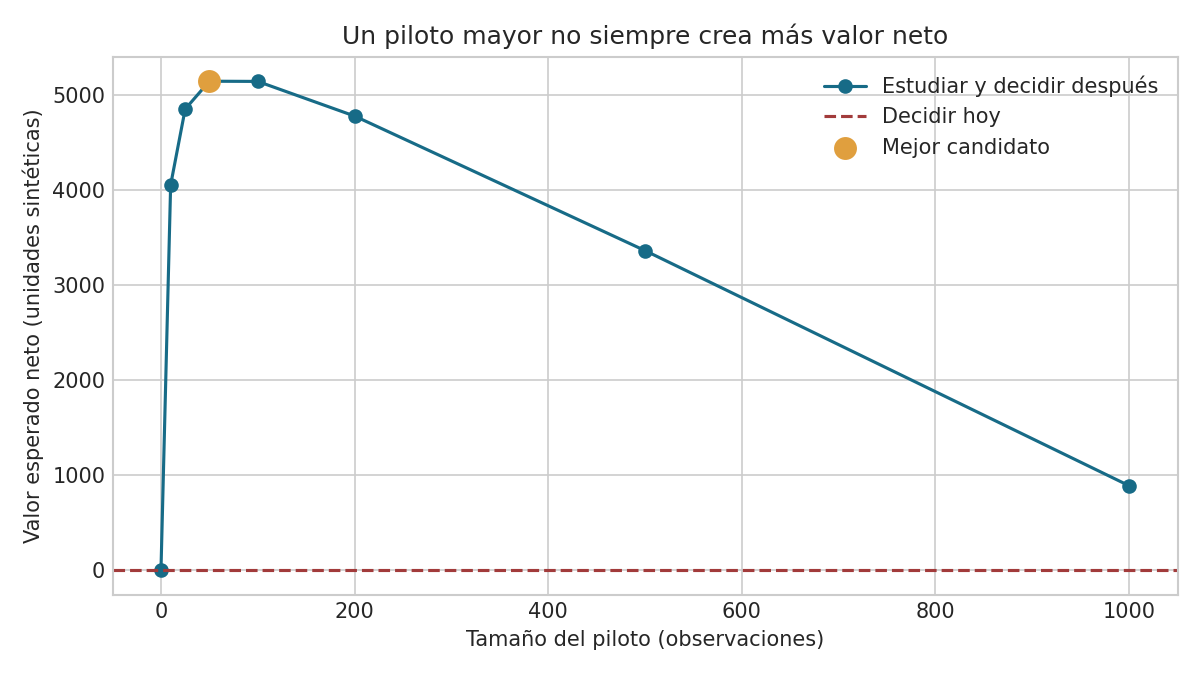

In [2]:
designs=pd.read_csv('results/designs.csv')
display(designs.round(3))
display(Image(filename='results/decision_curve.png'))

## Validación independiente por simulación
200.000 réplicas generan p y luego K, aplican la política a K y evalúan utilidad al p verdadero. El error estándar mide ruido MC bajo el modelo, no incertidumbre de negocio.

In [3]:
display({k:summary[k] for k in ['selected','evpi','mc_mean','mc_standard_error']})
assert abs(summary['mc_mean']-summary['selected']['net_value']) < 5*summary['mc_standard_error']
assert 0<=summary['selected']['evsi']<=summary['evpi']
assert summary['selected']['increment']>=cfg['hypothesis_min_increment']

{'selected': {'n': 50,
  'evsi': 5490.41839524532,
  'experiment_cost': 350.0,
  'net_value': 5140.41839524532,
  'immediate_value': 0.0,
  'increment': 5140.41839524532,
  'action': 'experimentar'},
 'evpi': 6019.743743999996,
 'mc_mean': 5153.613560613619,
 'mc_standard_error': 18.87000190645772}

## Sensibilidad y decisiones
Experimentar si el mejor valor neto supera decidir hoy. Escalar si la mejor opción sin estudio tiene utilidad positiva; detener en otro caso. Ajustar/rediseñar: variar costos, prior, horizonte y métricas si el piloto no es transferible. Esta herramienta no identifica efectos causales.

In [4]:
display(pd.read_csv('results/sensitivity.csv').round(3))

,prior_multiplier,study_unit_cost,n,evsi,experiment_cost,net_value,immediate_value,increment,action
0,1,0.0,1000,5989.853,100.0,5889.853,0.0,5889.853,experimentar
1,1,5.0,50,5490.418,350.0,5140.418,0.0,5140.418,experimentar
2,1,25.0,25,5072.303,725.0,4347.303,0.0,4347.303,experimentar
3,1,100.0,10,4201.000,1100.0,3101.000,0.0,3101.000,experimentar
4,5,0.0,1000,2683.111,100.0,2583.111,0.0,2583.111,experimentar
5,5,5.0,100,2242.906,600.0,1642.906,0.0,1642.906,experimentar
6,5,25.0,25,1576.244,725.0,851.244,0.0,851.244,experimentar
7,5,100.0,0,0.000,0.0,0.000,0.0,0.000,detener
8,20,0.0,1000,1259.847,100.0,1159.847,0.0,1159.847,experimentar
9,20,5.0,50,614.623,350.0,264.623,0.0,264.623,experimentar


## Conclusiones y límites
La información gratuita no empeora valor esperado; información costosa puede destruirlo. El n=100 casi empata n=50; no sobredimensionar esa diferencia. No se valida un producto IA real. La innovación es integrar un gate exacto auditable en un programa ejecutivo S1, no inventar EVSI. Referencias, fallos y rúbrica están en informe.md y referencias.bib.

## Laboratorio ampliado — derivación, usos y refutación

Experimentos adicionales del 23 de octubre de 2026. Datos sintéticos; las cifras guardadas del estudio original se conservan y las nuevas se recalculan debajo.

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'figure.figsize':(8,4.6),'font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18})
BLUE='#245B83'; GOLD='#B57A21'; GRAY='#4D5358'
rng_depth=np.random.default_rng(20261023)

### Valor de información y decisión de escalar

$$\theta\sim Beta(a,b),\quad K|\theta\sim Binomial(n,\theta),\quad E[\theta|K=k]=(a+k)/(a+b+n).$$

El valor de escalar es $V(\theta)=N(B\theta-c)-F$. La alternativa de no escalar vale cero. El piloto es separado de la población futura y sus costos no incluyen beneficios operacionales propios.

$$EVSI(n)=\sum_{k=0}^nP(K=k)\max\{0,V(E[\theta|k])\}-\max\{0,V(E\theta)\}.$$

$$\Delta(n)=EVSI(n)-C_0-nC_1.$$

Todas las cantidades monetarias usan una misma unidad sintética. Más información puede aumentar EVSI, pero el valor neto puede disminuir.

### Regla de decisión posterior

El umbral económico depende de beneficio, costo y gasto fijo, no de un 50% universal.

Umbral de éxito para escalar: 0.6


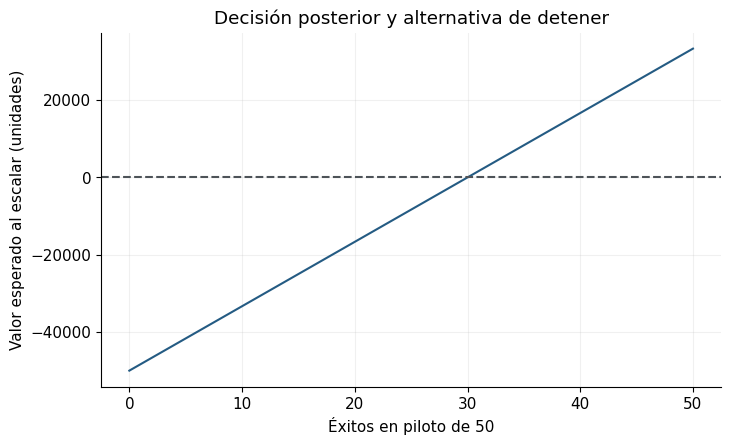

In [6]:
from src.evsi import Case, predictive, evaluate, choose
from dataclasses import replace
case_d=Case()
n_d=50
posterior=(case_d.alpha+np.arange(n_d+1))/(case_d.alpha+case_d.beta+n_d)
payoff=np.array([case_d.payoff(p) for p in posterior])
critical=(case_d.unit_cost+case_d.fixed_rollout/case_d.population)/case_d.benefit
print('Umbral de éxito para escalar:',critical)
fig,ax=plt.subplots();ax.plot(np.arange(n_d+1),payoff,color=BLUE);ax.axhline(0,color=GRAY,ls='--')
ax.set(xlabel='Éxitos en piloto de 50',ylabel='Valor esperado al escalar (unidades)',title='Decisión posterior y alternativa de detener');plt.show()

### Reconstrucción de EVSI

Comparación de enumeración manual de estados con la función pública.

In [7]:
mass=np.array(predictive(case_d,n_d))
manual_future=float(mass@np.maximum(payoff,0))
immediate=max(0,case_d.payoff(case_d.alpha/(case_d.alpha+case_d.beta)))
manual_evsi=manual_future-immediate
computed=evaluate(case_d,n_d)
assert abs(manual_evsi-computed['evsi'])<1e-8
assert abs(mass.sum()-1)<1e-12
print({'EVSI_manual':manual_evsi,'costo_piloto':computed['experiment_cost'],'incremento_neto':computed['increment']})

{'EVSI_manual': 5490.4183952453195, 'costo_piloto': 350.0, 'incremento_neto': 5140.41839524532}


### Diseño discreto y costo marginal

El máximo se restringe al grid mostrado; no es óptimo continuo ni una decisión secuencial.

,n,evsi,experiment_cost,net_value,immediate_value,increment,action
0,70,5628.302,450.0,5178.302,0.0,5178.302,experimentar


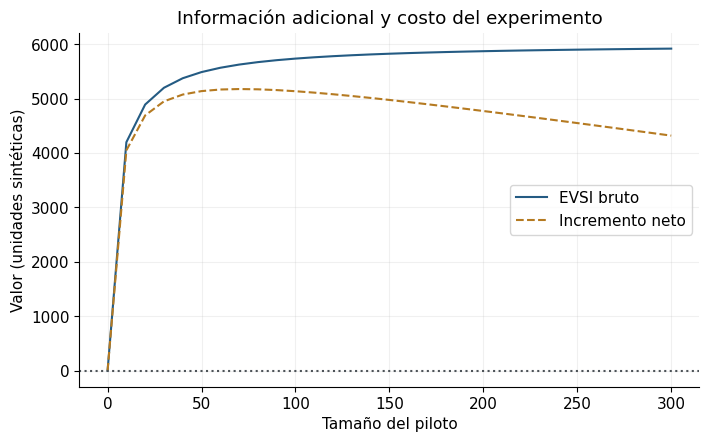

In [8]:
sizes=list(range(0,301,10))
design_d=pd.DataFrame([evaluate(case_d,n) for n in sizes])
selected=choose(case_d,sizes);display(pd.DataFrame([selected]).round(3))
fig,ax=plt.subplots();ax.plot(design_d.n,design_d.evsi,label='EVSI bruto',color=BLUE)
ax.plot(design_d.n,design_d.increment,label='Incremento neto',color=GOLD,ls='--');ax.axhline(0,color=GRAY,ls=':')
ax.set(xlabel='Tamaño del piloto',ylabel='Valor (unidades sintéticas)',title='Información adicional y costo del experimento');ax.legend();plt.show()

### Prior y escala de despliegue

Cambiar la población futura modifica el valor de aprender. El prior se explicita y no se elige con resultados futuros.

In [9]:
sensitivity_d=[]
for a,b in [(2,8),(6,4),(8,2)]:
    for population in [1000,10000,50000]:
        cc=replace(case_d,alpha=a,beta=b,population=population)
        choice=choose(cc,sizes)
        sensitivity_d.append({'a':a,'b':b,'N':population,'n_elegido':choice['n'],'incremento':choice['increment']})
display(pd.DataFrame(sensitivity_d).round(2))

,a,b,N,n_elegido,incremento
0,2,8,1000,0,0.00
1,2,8,10000,0,0.00
2,2,8,50000,0,0.00
3,6,4,1000,20,289.36
4,6,4,10000,70,5178.30
5,6,4,50000,170,28298.17
6,8,2,1000,0,0.00
7,8,2,10000,30,43.07
8,8,2,50000,90,1593.56


### Cota de información perfecta

Integración independiente del prior beta. La cota es ex ante, no desempeño observado del producto.

In [10]:
from scipy.integrate import quad
from scipy.stats import beta as beta_dist
evpi_d=quad(lambda theta:max(0,case_d.payoff(theta))*beta_dist.pdf(theta,case_d.alpha,case_d.beta),0,1,points=[critical])[0]-immediate
assert design_d.evsi.min()>-1e-7
assert design_d.evsi.max()<=evpi_d+1e-6
assert evaluate(case_d,0)['increment']==0
print({'EVPI_integracion':evpi_d,'max_EVSI_grid':design_d.evsi.max()})

{'EVPI_integracion': 6019.743744, 'max_EVSI_grid': np.float64(5921.687178128002)}


### Uso para dirección e innovación

El criterio compara aprender, escalar y detener con costos explícitos. Separa calidad del experimento de tamaño de mercado y evita imponer un piloto por costumbre. Faltan abandono secuencial, demora, heterogeneidad, competencia y validación del prior; no interpretar el máximo sintético como presupuesto empresarial recomendado.

### Preguntas para extender el estudio

1. ¿Qué supuesto permite el resultado y qué contraejemplo lo destruye?
2. ¿Qué cambia al separar entrenamiento, calibración y evaluación por fecha?
3. ¿Qué pérdidas, costos o acciones no están representados?
4. ¿Qué evidencia real haría abandonar este modelo?

Las salidas anteriores son el resultado de esta ejecución; las pruebas locales no establecen validez empírica.

### EVSI con prior de igual media y distinta certeza

La media no resume el valor de aprender: se cambia concentración del prior manteniendo E(theta)=0.6.

,concentracion,media,n_elegido,EVSI,incremento
0,2,0.6,50,11935.305,11585.305
1,5,0.6,60,7966.307,7566.307
2,10,0.6,70,5628.302,5178.302
3,30,0.6,80,3013.656,2513.656
4,100,0.6,70,1248.048,798.048


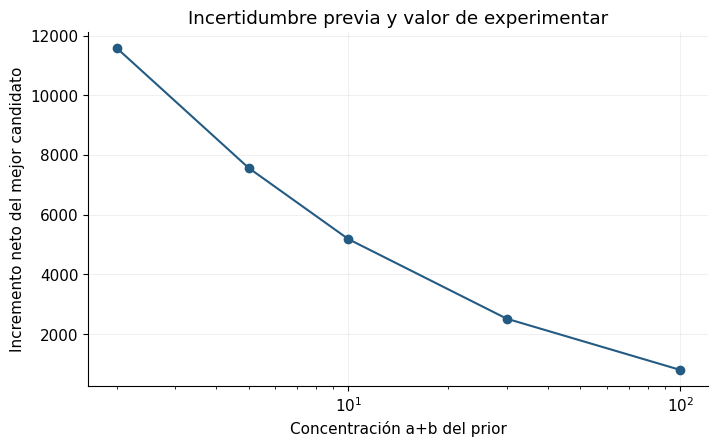

In [11]:
prior_rows=[]
for concentration in [2,5,10,30,100]:
    candidate=replace(case_d,alpha=.6*concentration,beta=.4*concentration)
    best=choose(candidate,sizes)
    prior_rows.append({'concentracion':concentration,'media':.6,'n_elegido':best['n'],'EVSI':best['evsi'],'incremento':best['increment']})
prior_table=pd.DataFrame(prior_rows)
display(prior_table.round(3))
fig,ax=plt.subplots()
ax.plot(prior_table.concentracion,prior_table.incremento,'o-',color=BLUE)
ax.set(xscale='log',xlabel='Concentración a+b del prior',ylabel='Incremento neto del mejor candidato',title='Incertidumbre previa y valor de experimentar')
plt.show()

### Demora y valor neto

Se incorpora una penalidad hipotética por día. Esto es sensibilidad estática, no un modelo dinámico de competencia.

In [12]:
delay_rows=[]
for cost_per_day in [0,25,100]:
    adjusted=design_d.copy()
    adjusted['dias']=np.where(adjusted.n>0,5+adjusted.n/10,0)
    adjusted['neto_con_demora']=adjusted.increment-cost_per_day*adjusted.dias
    best=adjusted.loc[adjusted.neto_con_demora.idxmax()]
    delay_rows.append({'costo_dia':cost_per_day,'n':best.n,'incremento_neto':best.neto_con_demora})
display(pd.DataFrame(delay_rows).round(2))

,costo_dia,n,incremento_neto
0,0,70.0,5178.30
1,25,60.0,4894.70
2,100,40.0,4177.13


### El piloto puede no pagar su costo

La alternativa n=0 permanece disponible. Los costos no se restan dos veces al comparar contra decidir hoy.

In [13]:
expensive=replace(case_d,experiment_fixed=1000000.)
no_study=choose(expensive,sizes)
assert no_study['n']==0
assert no_study['increment']==0
print(no_study)
# Con información inútil, comprarla tampoco se justifica.
zero_population=replace(case_d,population=0)
assert choose(zero_population,sizes)['n']==0

{'n': 0, 'evsi': 0.0, 'experiment_cost': 0.0, 'net_value': 0.0, 'immediate_value': 0.0, 'increment': 0.0, 'action': 'detener'}


### Interpretación de las pruebas adicionales

Cada experimento modifica un supuesto concreto. Las comparaciones conservan denominadores, unidades y desconocidos; los resultados negativos forman parte de la evidencia. Las simulaciones no convierten un diseño en un sistema operativo ni sustituyen validación independiente con datos aprobados.

## Ampliación académica: literatura, fórmulas y experimento

Consulta bibliográfica del 23 de octubre de 2026. Se distingue método publicado, derivación propia y experimento sintético. El [mapa bibliográfico](https://github.com/Jose85100/Portafolio/blob/research/2026-10-23-multi-domain-cycle/reviews/2026-10-23-academic/README.md) en la raíz del repositorio registra publicaciones, acceso y brechas; las fuentes específicas se enlazan debajo.

### Piloto secuencial: detener, escalar o seguir aprendiendo

Marco de utilidad esperada: [Chaloner y Verdinelli, Statistical Science 1995](https://doi.org/10.1214/ss/1177009939). La recursión finita que sigue es una aplicación propia del principio de Bellman al modelo existente, no una reproducción de un algoritmo del artículo.

$$W(a,b,h)=\max\{0,V(a/(a+b)),\ -c_s+\tfrac{a}{a+b}W(a+1,b,h-1)+\tfrac{b}{a+b}W(a,b+1,h-1)\}.$$

Para $h=0$ solo se puede detener o escalar. El costo de apertura se descuenta una sola vez en la raíz. Los sujetos del piloto son separados de la población futura; no hay beneficio durante experimentación.

### Programación dinámica finita con memoización

Se incluye siempre no estudiar. El horizonte máximo es 30 observaciones; el estado es posterior beta más presupuesto restante.

In [14]:
from functools import lru_cache
case_seq=Case(experiment_fixed=20.,experiment_unit=20.)
@lru_cache(None)
def sequential_value(a,b,remaining):
    stop=max(0.,case_seq.payoff(a/(a+b)))
    if remaining==0:return stop
    continuation=-case_seq.experiment_unit+(a/(a+b))*sequential_value(a+1,b,remaining-1)+(b/(a+b))*sequential_value(a,b+1,remaining-1)
    return max(stop,continuation)

horizon=30
immediate_seq=max(0.,case_seq.payoff(case_seq.alpha/(case_seq.alpha+case_seq.beta)))
seq_net=max(immediate_seq,sequential_value(case_seq.alpha,case_seq.beta,horizon)-case_seq.experiment_fixed)
fixed_grid=list(range(horizon+1))
fixed_best=choose(case_seq,fixed_grid)
assert seq_net>=fixed_best['net_value']-1e-7
assert sequential_value(case_seq.alpha,case_seq.beta,0)==immediate_seq
print({'secuencial_neto':seq_net,'mejor_fijo_neto':fixed_best['net_value'],'ventaja':seq_net-fixed_best['net_value']})

{'secuencial_neto': 4796.377133033429, 'mejor_fijo_neto': 4601.805220780544, 'ventaja': 194.57191225288534}


### Mapa de continuación según éxitos acumulados

Las decisiones se calculan antes de observar resultados futuros. El experimento sintético no evalúa sesgo de selección de usuarios o efectos de demorar el lanzamiento.

ACADEMIC_METRICS:{"sequential_value": 4796.377133033429, "fixed_best_value": 4601.805220780544, "horizon": 30, "states": 496}


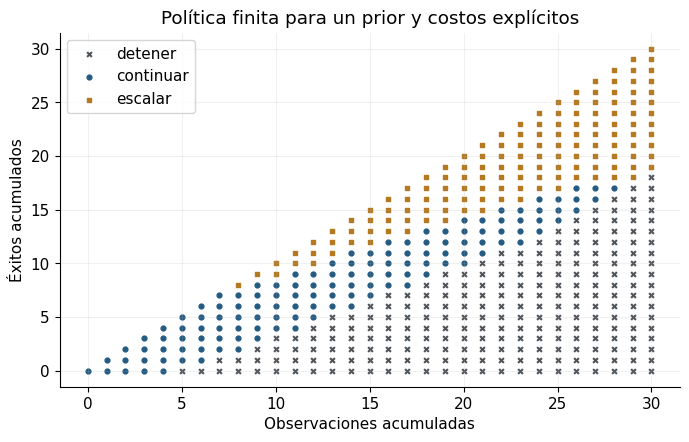

In [15]:
state_rows=[]
for observed in range(horizon+1):
    for successes in range(observed+1):
        a=case_seq.alpha+successes;b=case_seq.beta+observed-successes
        stop=max(0.,case_seq.payoff(a/(a+b)))
        remaining=horizon-observed
        cont=(-case_seq.experiment_unit+(a/(a+b))*sequential_value(a+1,b,remaining-1)+(b/(a+b))*sequential_value(a,b+1,remaining-1)) if remaining else -np.inf
        action='continuar' if cont>stop else ('escalar' if stop>0 else 'detener')
        state_rows.append({'observed':observed,'successes':successes,'action':action})
state_table=pd.DataFrame(state_rows)
fig,ax=plt.subplots()
for name,color,marker in [('detener',GRAY,'x'),('continuar',BLUE,'o'),('escalar',GOLD,'s')]:
    sub=state_table[state_table.action==name]
    ax.scatter(sub.observed,sub.successes,s=12,color=color,marker=marker,label=name)
ax.set(xlabel='Observaciones acumuladas',ylabel='Éxitos acumulados',title='Política finita para un prior y costos explícitos')
ax.legend();plt.show()
import json
print('ACADEMIC_METRICS:'+json.dumps({'sequential_value':seq_net,'fixed_best_value':float(fixed_best['net_value']),'horizon':horizon,'states':len(state_rows)}))

### Oráculo por enumeración de políticas, horizonte tres

Se enumeran 128 reglas binarias de continuar/parar sobre el árbol completo. Se evalúa cada política por probabilidades de camino, separada de la recursión memoizada.

In [16]:
from itertools import product
small_horizon=3
policy_values=[]
for bits in product([0,1],repeat=2**small_horizon-1):
    # Node heap: root=0, success=2*j+1, failure=2*j+2.
    frontier=[(0,case_seq.alpha,case_seq.beta,0,1.,0.)]
    total=0.
    while frontier:
        node,a,b,depth,mass,spent=frontier.pop()
        stop=depth==small_horizon or bits[node]==0
        if stop:
            total+=mass*(max(0.,case_seq.payoff(a/(a+b)))-spent)
        else:
            p_success=a/(a+b)
            new_spent=spent+case_seq.experiment_unit
            frontier.append((2*node+1,a+1,b,depth+1,mass*p_success,new_spent))
            frontier.append((2*node+2,a,b+1,depth+1,mass*(1-p_success),new_spent))
    policy_values.append(total)
oracle=max(policy_values)
dp=sequential_value(case_seq.alpha,case_seq.beta,small_horizon)
assert abs(oracle-dp)<1e-7
print({'policies_enumerated':len(policy_values),'oracle_DP_gap':abs(oracle-dp)})

{'policies_enumerated': 128, 'oracle_DP_gap': 0.0}


### Ideas y cierre pendiente

Contrastar el valor con un oráculo por enumeración para horizonte corto y con simulación fuera de la política ajustada; después introducir heterogeneidad, costo de demora y prior robusto. La desigualdad secuencial ≥ fijo solo se sostiene con el mismo menú, horizonte y costos.